<>:35: SyntaxWarning: invalid escape sequence '\c'
<>:35: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_2830418/2956151631.py:35: SyntaxWarning: invalid escape sequence '\c'
  axes[0].axvline(1.0, color='green', linestyle=':', label='Ideal ($\chi^2_{red} = 1$)')


  analysing data from /home/holman/HIIGalaxies/Bayesian_samplers/Multinest/MAIN/D/D.2_Standard/D.2_.txt
Mejor chi^2 reducido: 3.424
Parámetros de mejor ajuste: [33.27537111  5.00012298  0.72452816  0.25349892 -0.81164967]


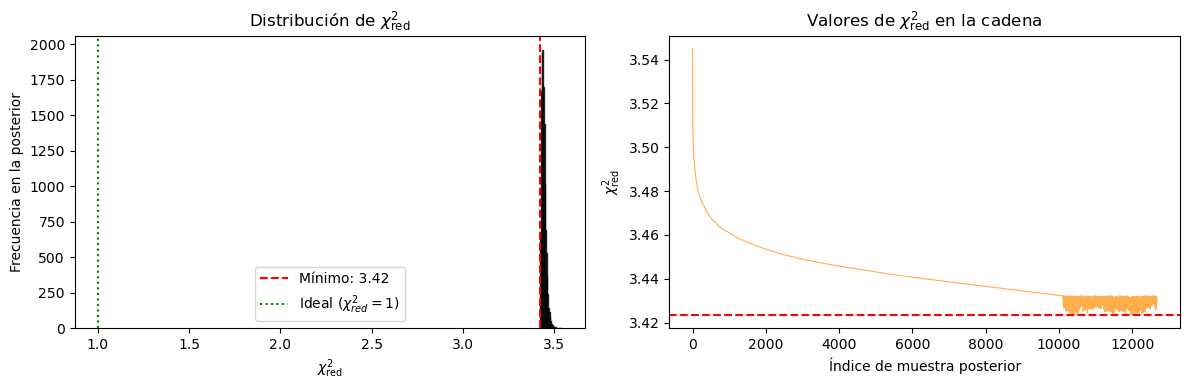

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pymultinest

# 1. Configuración de tu modelo y archivos
n_params = 5                  # Número de parámetros libres (k)
n_data = 243                   # Número de puntos de datos (N)
dof = n_data - n_params       # Grados de libertad (v)
prefix = "/home/holman/HIIGalaxies/Bayesian_samplers/Multinest/MAIN/D/D.2_Standard/D.2_"  # Prefijo usado en outputfiles_basename

# 2. Cargar la cadena posterior con pesos iguales
analyzer = pymultinest.Analyzer(n_params=n_params, outputfiles_basename=prefix)
samples = analyzer.get_equal_weighted_posterior()

# La última columna de 'samples' es siempre log(L)
loglike = samples[:, -1]

# 3. Convertir a chi^2 y chi^2 reducido
# Nota: Si incluiste normalización en loglike, usa: chi2 = -2 * (loglike - norm)
chi2 = -2.0 * loglike
chi2_red = chi2 / dof

# 4. Imprimir el mejor ajuste (mínimo chi^2 reducido)
best_idx = np.argmin(chi2_red)
best_params = samples[best_idx, :-1]
print(f"Mejor chi^2 reducido: {chi2_red[best_idx]:.3f}")
print(f"Parámetros de mejor ajuste: {best_params}")

# 5. Visualización
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfica A: Distribución (Histograma) del chi^2 reducido en la cadena
axes[0].hist(chi2_red, bins=30, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].axvline(chi2_red[best_idx], color='red', linestyle='--', label=f'Mínimo: {chi2_red[best_idx]:.2f}')
axes[0].axvline(1.0, color='green', linestyle=':', label='Ideal ($\chi^2_{red} = 1$)')
axes[0].set_xlabel(r'$\chi^2_{\mathrm{red}}$')
axes[0].set_ylabel('Frecuencia en la posterior')
axes[0].set_title(r'Distribución de $\chi^2_{\mathrm{red}}$')
axes[0].legend()

# Gráfica B: Traza de chi^2 reducido a lo largo de las muestras posteriores
axes[1].plot(chi2_red, color='darkorange', alpha=0.7, linewidth=0.8)
axes[1].axhline(chi2_red[best_idx], color='red', linestyle='--')
axes[1].set_xlabel('Índice de muestra posterior')
axes[1].set_ylabel(r'$\chi^2_{\mathrm{red}}$')
axes[1].set_title(r'Valores de $\chi^2_{\mathrm{red}}$ en la cadena')

plt.tight_layout()
plt.show()
